# 03 — Clean bubbles and match GT
No models. Empty GT pages remain available for manual attribution.

Settings are included in each cache key. Per-page empty IDs use sequence/page keys.

In [10]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "project.json").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pipeline_helpers as P
import json
from PIL import Image, ImageDraw, ImageFont
ROOT = P.ROOT
MODELS = P.read_json(ROOT / "models.json")
SPLITS = ["train", "val"]  # Or ["train"] / ["val"].
FORCE_RERUN = False
items = P.pages(SPLITS)
print("Pages:", len(items))
DELETE_EMPTY_BUBBLES = True
EMPTY_IDS_BY_PAGE = {}  # Example: {"seq_71033fec4de494fc/2": ["B16"]}
MIN_OVERLAP = 0.80
MIN_MATCH_SCORE = 80.0

MIN_PARTIAL_WORDS = 3  # Exact partial OCR phrases must have at least 3 words.


Pages: 240


GT matching order: exact full text, exact partial phrase (at least three words), then the existing fuzzy comparison. 
Exact phrases matching different speakers remain unresolved. Matching cache version 2 recomputes GT attribution 
on your next run while retaining raw bubble/OCR caches. Saved manual labels and exports may require review after GT results change.


Remove empty bubbles optionally and overlapping duplicates with the same text.

In [11]:
for item in items:
    PAGE = Path(item["image_path"])
    page = Image.open(PAGE).convert("RGB")
    OUT = P.page_folder(item)
    OUT.mkdir(parents=True, exist_ok=True)
    settings = {"delete_empty":DELETE_EMPTY_BUBBLES, "empty_ids":EMPTY_IDS_BY_PAGE.get(f"{item['sequence_id']}/{item['page_number']}", []), "overlap":MIN_OVERLAP, "version":1}
    dependencies = [OUT / "bubbles.json", OUT / "ocr.json"]
    def save_stage(name, records):
        P.save_stage(item, name, records, settings, dependencies)
    def load_stage(name):
        return P.load_stage(item, name)
    if all(P.cached(item, name, settings, dependencies, FORCE_RERUN) for name in ['bubbles_clean.json', 'ocr_clean.json']):
        print("Cached:", item["split"], item["sequence_id"], item["page_number"])
        continue
    bubbles = load_stage("bubbles.json")
    ocr_results = load_stage("ocr.json")
    EMPTY_BUBBLES_TO_DELETE = EMPTY_IDS_BY_PAGE.get(f"{item['sequence_id']}/{item['page_number']}", [])
    def normalize_text(text):
        return " ".join(text.upper().split())

    def box_area(box):
        x1, y1, x2, y2 = box
        return max(0, x2 - x1) * max(0, y2 - y1)

    ocr_by_id = {record["bubble_id"]: record for record in ocr_results}
    kept_bubbles = []
    empty_ids = [r["bubble_id"] for r in ocr_results if not r["text"].strip()]
    invalid_ids = set(EMPTY_BUBBLES_TO_DELETE) - set(empty_ids)
    if invalid_ids:
        raise ValueError(f"These IDs are missing or have non-empty OCR: {sorted(invalid_ids)}")
    removed_empty_ids = [bubble_id for bubble_id in empty_ids
                         if DELETE_EMPTY_BUBBLES or bubble_id in EMPTY_BUBBLES_TO_DELETE]
    removed_ids = removed_empty_ids.copy()

    # Check larger boxes first so a duplicate inner box is removed.
    for bubble in sorted(bubbles, key=lambda b: box_area(b["box"]), reverse=True):
        if bubble["bubble_id"] in removed_empty_ids:
            print(f"Remove {bubble['bubble_id']}: no OCR text found")
            continue
        text = normalize_text(ocr_by_id[bubble["bubble_id"]]["text"])
        duplicate = False
        for kept in kept_bubbles:
            kept_text = normalize_text(ocr_by_id[kept["bubble_id"]]["text"])
            if not text or text != kept_text:
                continue
            x1, y1, x2, y2 = bubble["box"]
            kx1, ky1, kx2, ky2 = kept["box"]
            intersection = max(0, min(x2, kx2) - max(x1, kx1)) * max(0, min(y2, ky2) - max(y1, ky1))
            smaller_area = min(box_area(bubble["box"]), box_area(kept["box"]))
            if smaller_area > 0 and intersection / smaller_area >= MIN_OVERLAP:
                duplicate = True
                print(f"Remove {bubble['bubble_id']}: duplicate of {kept['bubble_id']}")
                break
        if duplicate:
            removed_ids.append(bubble["bubble_id"])
        else:
            kept_bubbles.append(bubble)

    # Keep the original order/IDs. Non-empty unmatched OCR bubbles stay.
    clean_bubbles = [b for b in bubbles if b["bubble_id"] not in removed_ids]
    clean_ocr = [r for r in ocr_results if r["bubble_id"] not in removed_ids]
    save_stage("bubbles_clean.json", clean_bubbles)
    save_stage("ocr_clean.json", clean_ocr)
    print(f"Kept {len(clean_bubbles)} bubbles; removed {len(removed_empty_ids)} empty bubbles "
          f"and {len(removed_ids) - len(removed_empty_ids)} duplicates.")


Cached: train seq_2032620aa4e4ac7f 1
Cached: train seq_2032620aa4e4ac7f 2
Cached: train seq_2032620aa4e4ac7f 3
Cached: train seq_952f154fb1505883 1
Cached: train seq_952f154fb1505883 2
Cached: train seq_952f154fb1505883 3
Cached: train seq_7db7a000adeceacf 1
Cached: train seq_7db7a000adeceacf 2
Cached: train seq_7db7a000adeceacf 3
Cached: train seq_9032e5551cf1a9d2 1
Cached: train seq_9032e5551cf1a9d2 2
Cached: train seq_9032e5551cf1a9d2 3
Cached: train seq_2022b8c0e1f2d3c0 1
Cached: train seq_2022b8c0e1f2d3c0 2
Cached: train seq_2022b8c0e1f2d3c0 3
Cached: train seq_a3bd36201a0cd61b 1
Cached: train seq_a3bd36201a0cd61b 2
Cached: train seq_a3bd36201a0cd61b 3
Cached: train seq_72fdfff4b4353a42 1
Cached: train seq_72fdfff4b4353a42 2
Cached: train seq_72fdfff4b4353a42 3
Cached: train seq_b251c8e1ba8b91f8 1
Cached: train seq_b251c8e1ba8b91f8 2
Cached: train seq_b251c8e1ba8b91f8 3
Cached: val seq_ee880b9612205860 1
Cached: val seq_ee880b9612205860 2
Cached: val seq_ee880b9612205860 3
Cached:

One best transcript match. Weak/unmatched bubbles are kept for review.

In [12]:
import importlib
import transcript_matching
importlib.reload(transcript_matching)
from transcript_matching import match_transcript

for item in items:
    PAGE = Path(item["image_path"])
    page = Image.open(PAGE).convert("RGB")
    OUT = P.page_folder(item)
    OUT.mkdir(parents=True, exist_ok=True)
    settings = {"minimum_score":MIN_MATCH_SCORE, "minimum_partial_words":MIN_PARTIAL_WORDS, "version":2}
    dependencies = [OUT / "ocr_clean.json", Path(P.split_manifest()["labels_path"])]
    def save_stage(name, records):
        P.save_stage(item, name, records, settings, dependencies)
    def load_stage(name):
        return P.load_stage(item, name)
    if all(P.cached(item, name, settings, dependencies, FORCE_RERUN) for name in ['bubble_gt_labels.json']):
        print("Cached:", item["split"], item["sequence_id"], item["page_number"])
        continue
    from difflib import SequenceMatcher
    sequence = P.gt_sequence(item)
    clean_ocr = load_stage("ocr_clean.json")
    def normalize_text(text):
        return " ".join(text.upper().split())
    gt_dialogue = sequence["pages"][item["page_number"] - 1]

    bubble_gt_labels = []
    for record in clean_ocr:
        label = match_transcript(record, gt_dialogue,
                                 minimum_score=MIN_MATCH_SCORE,
                                 minimum_partial_words=MIN_PARTIAL_WORDS)
        bubble_gt_labels.append(label)
        print(f"{label['bubble_id']} -> {label['speaker']} ({label['match_type']}, {label['match_score']}): {record['text']}")

    # No bubble is excluded because its GT match is weak or missing.
    # GT speaker names are identities, not the detector's C appearance IDs.
    save_stage("bubble_gt_labels.json", {
        "sequence_id": item["sequence_id"],
        "page_number": item["page_number"],
        "bubbles": bubble_gt_labels,
    })


B3 -> character1 (exact, 100.0): HUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?
B4 -> None (unmatched, 50.9): HE'S DOING REALLY WELL. R NT.
B5 -> character2 (fuzzy, 82.4): IT LOOKS R LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT.
B6 -> character1 (exact, 100.0): NO, THAT'S NOT IT. IT'S LIKE HE'S...
B7 -> character1 (exact, 100.0): OUT FOR BLOOD.
B1 -> None (unmatched, 0.0): TIME LAST
B2 -> None (unmatched, 0.0): STILL NOT SURE OF HIS CHOICES. NOW, THE SEASONS CHANGE AND AUTUMN BEGINS... BEGAN... AND HACHIKEN USED THE MONEY HE EARNED TO BUY PORK BOWL'S MEAT, BUT HE'S SUMMER VACATION... HACHIKEN SPENT THE WHOLE TIME WORKING AT AKI'S. THE NEW TERM
B1 -> UNKNOWN (exact, 100.0): WOAH!!
B2 -> character3 (fuzzy, 98.4): OKAWA- SENPAI, YOU LOOK SO COOL!
B3 -> character4 (exact, 100.0): RIGHT HERE! THIS IS WHERE IT HAPPENS!
B4 -> UNKNOWN (fuzzy, 95.2): so CLOSE !!
B5 -> None (unmatched, 26.7): CLACK
B6 -> character5 (fuzzy, 98.1): DO YOU HAVE TO KEEP WATCHING THAT? IT'S EMBAR- RASSING.
B7 -> 

## View saved results
These cells only read saved results. They do not run models or change cached files. Training shows targets and run-wide loss history; validation shows saved predictions.

In [13]:
from pathlib import Path
import sys, importlib
view_root = Path.cwd().resolve()
if not (view_root / "project.json").is_file():
    view_root = view_root.parent
sys.path.insert(0, str(view_root))
import result_viewer as V
importlib.reload(V)
VIEW_STAGE = 'cleanup'
VIEW_SPLIT = "train"  # Or "val".
VIEW_RUN = None


### 1. View a random page
Rerun this cell to choose another page with a saved result in this split.


train | seq_5f9ee35846b7e635 | page 1


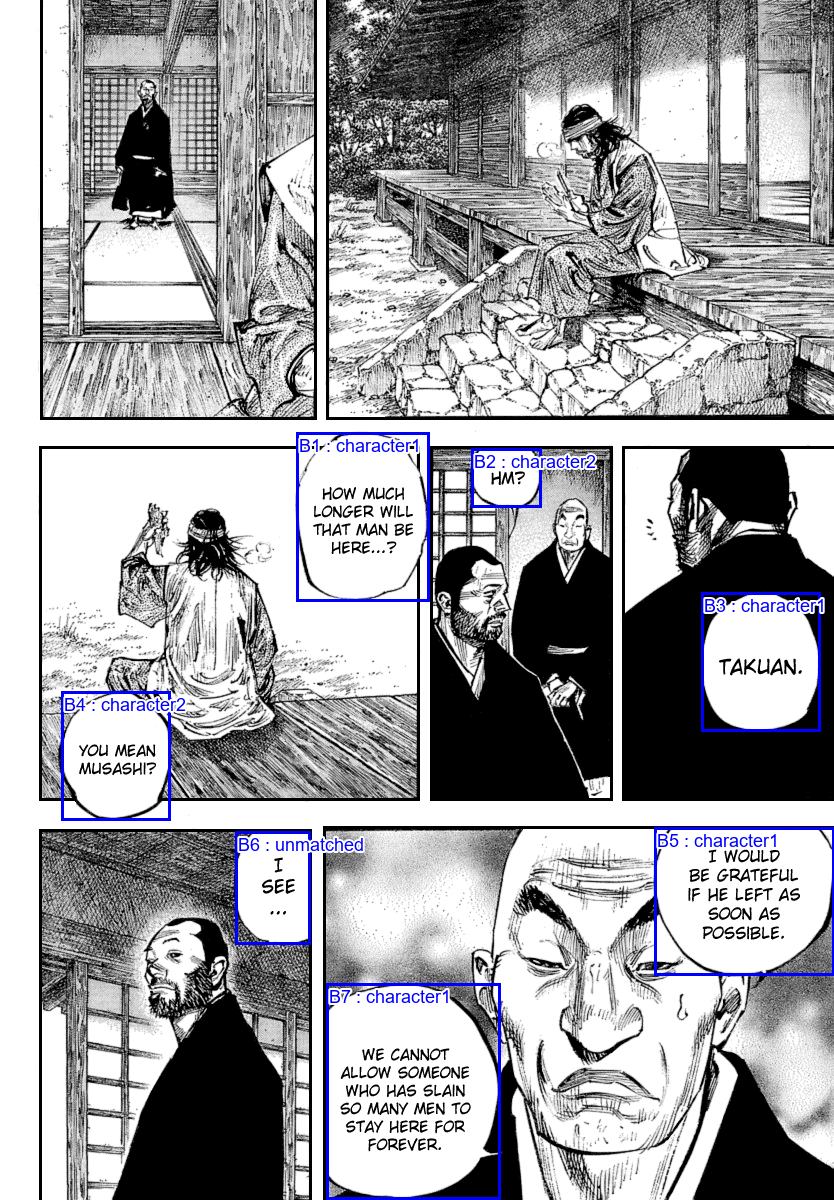

[
  {
    "bubble_id": "B1",
    "text": "HOW MUCH LONGER WILL THAT MAN BE HERE...?",
    "gt_index": 2,
    "gt_text": "HOW MUCH LONGER WILL THAT MAN BE HERE...?",
    "speaker": "character1",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B2",
    "text": "HM?",
    "gt_index": 1,
    "gt_text": "HM?",
    "speaker": "character2",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B3",
    "text": "TAKUAN.",
    "gt_index": 0,
    "gt_text": "TAKUAN.",
    "speaker": "character1",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B4",
    "text": "YOUI MEAN MUSASHI?",
    "gt_index": 3,
    "gt_text": "YOU MEAN MUSASHI?",
    "speaker": "character2",
    "match_score": 97.1,
    "match_type": "fuzzy"
  },
  {
    "bubble_id": "B5",
    "text": "I WOULD BE GRATEFUL IF HE LEFT AS SOON AS POSSIBLE.",
    "gt_index": 4,
    "gt_text": "I WOULD BE GRATEFUL IF HE LEFT AS SOON AS POSSIBLE.",
    "speake

In [14]:
viewed_page = V.show_random(VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)


### 2. View all pages of a sequence
Enter a sequence ID, or leave it empty to use the random page’s sequence. Missing stage results are reported for each page.


train | seq_b9b5a9ad9a64ced9 | page 1


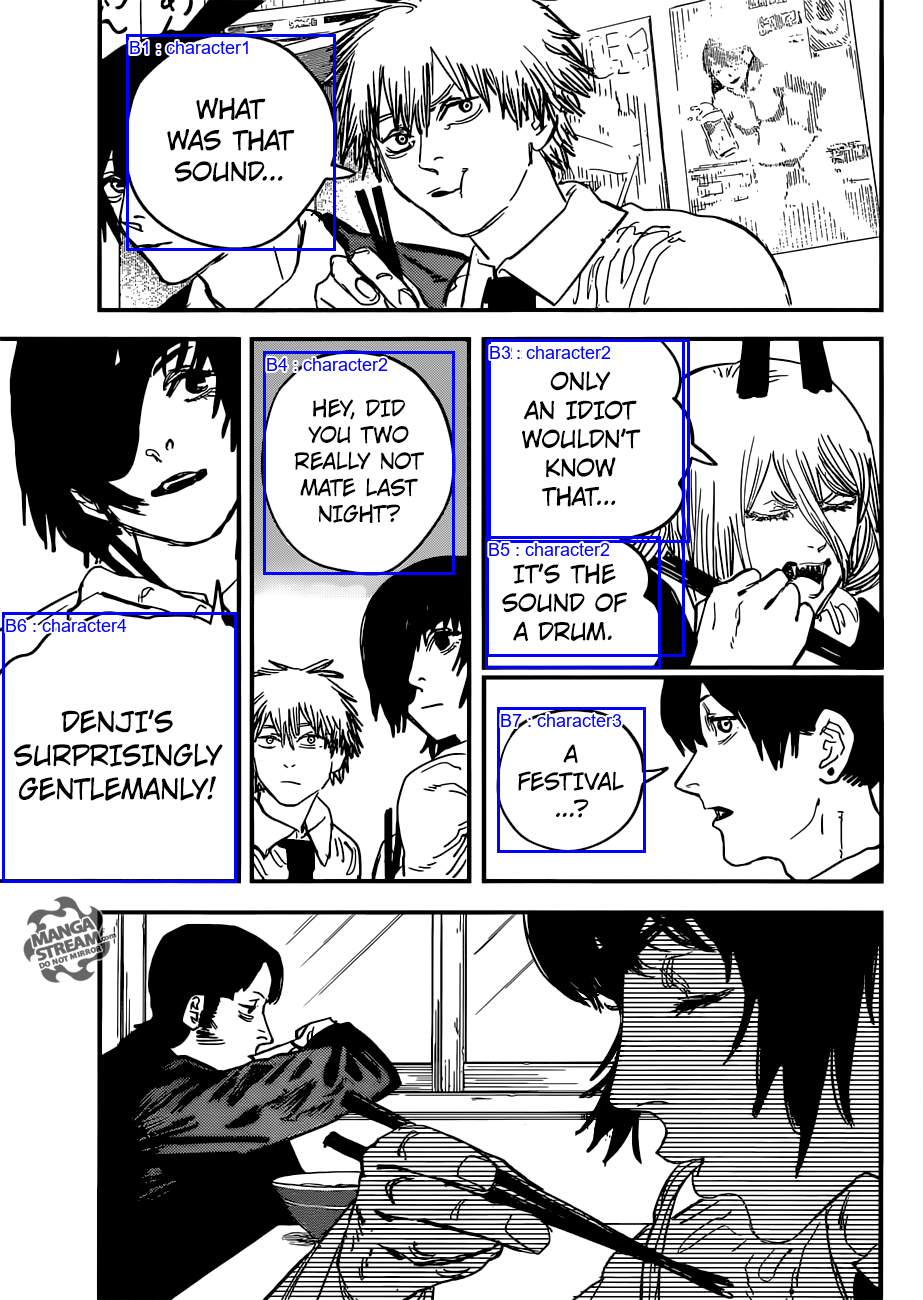

[
  {
    "bubble_id": "B1",
    "text": "WHAT WAS THAT SOUND...",
    "gt_index": 0,
    "gt_text": "WHAT WAS THAT SOUND...",
    "speaker": "character1",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B2",
    "text": "ONLY AN IDIOT WOULDN'T KNOW THAT...",
    "gt_index": 1,
    "gt_text": "ONLY AN IDIOT WOULDN'T KNOW THAT... IT'S THE SOUND OF A DRUM.",
    "speaker": "character2",
    "match_score": 100.0,
    "match_type": "exact_partial"
  },
  {
    "bubble_id": "B3",
    "text": "ONLY AN IDIOT WOULDN'T KNOW THAT... IT'S THE SOUND OF A DRUM.",
    "gt_index": 1,
    "gt_text": "ONLY AN IDIOT WOULDN'T KNOW THAT... IT'S THE SOUND OF A DRUM.",
    "speaker": "character2",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B4",
    "text": "HEY, DID YOU TWO REALLY NOT MATE LAST NIGHT?",
    "gt_index": 3,
    "gt_text": "HEY, DID YOU TWO REALLY NOT MATE LAST NIGHT?",
    "speaker": "character2",
    "match_score": 100.0,
   

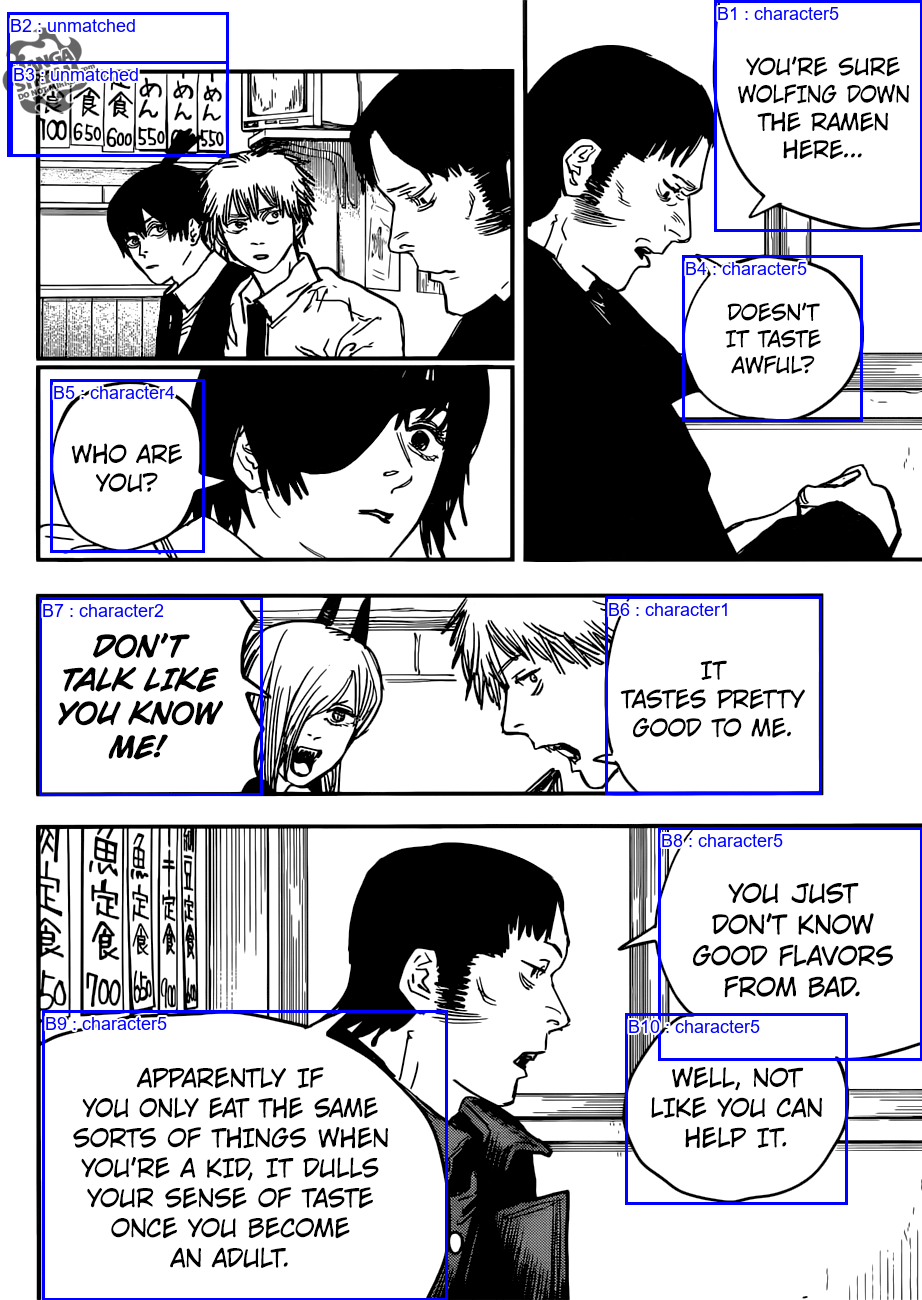

[
  {
    "bubble_id": "B1",
    "text": "YOU'RE SURE WOLFING DOWN THE RAMEN HERE...",
    "gt_index": 0,
    "gt_text": "YOU'RE SURE WOLFING DOWN THE RAMEN HERE...",
    "speaker": "character5",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B2",
    "text": "MANGA 正食600 食69 あん5 STREA あん めん 10",
    "gt_index": null,
    "gt_text": null,
    "speaker": null,
    "match_score": 25.8,
    "match_type": "unmatched"
  },
  {
    "bubble_id": "B3",
    "text": "正食600 おん5 あん 食 めん5 100 650",
    "gt_index": null,
    "gt_text": null,
    "speaker": null,
    "match_score": 21.1,
    "match_type": "unmatched"
  },
  {
    "bubble_id": "B4",
    "text": "DOESN'T IT TASTE AWFUL?",
    "gt_index": 1,
    "gt_text": "DOESN'T IT TASTE AWFUL?",
    "speaker": "character5",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B5",
    "text": "WHO ARE YOU?",
    "gt_index": 2,
    "gt_text": "WHO ARE YOU?",
    "speaker": "character4",
    "m

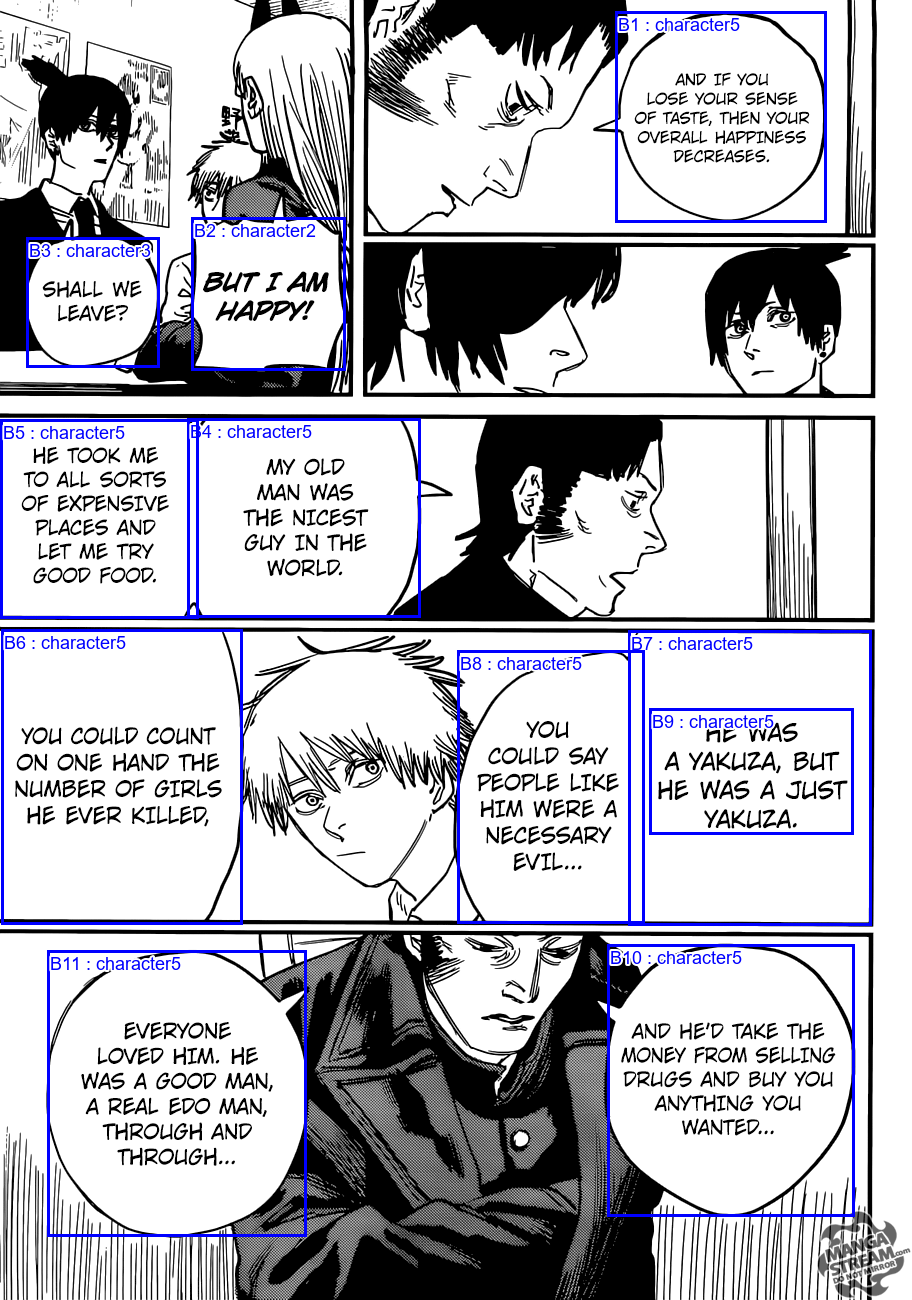

[
  {
    "bubble_id": "B1",
    "text": "AND IF YOU LOSE YOUR SENSE OF TASTE, THEN YOUR OVERALL HAPPINESS DECREASES.",
    "gt_index": 0,
    "gt_text": "AND IF YOU LOSE YOUR SENSE OF TASTE, THEN YOUR OVERALL HAPPINESS DECREASES.",
    "speaker": "character5",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B2",
    "text": "BUT I AM HAPPY!",
    "gt_index": 1,
    "gt_text": "BUT I AM HAPPY!",
    "speaker": "character2",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B3",
    "text": "SHALL WE LEAVE?",
    "gt_index": 2,
    "gt_text": "SHALL WE LEAVE?",
    "speaker": "character3",
    "match_score": 100.0,
    "match_type": "exact"
  },
  {
    "bubble_id": "B4",
    "text": "MY OLD MAN WAS THE NICEST GLUY IN THE WORLD. A",
    "gt_index": 3,
    "gt_text": "MY OLD MAN WAS THE NICEST GUY IN THE WORLD.",
    "speaker": "character5",
    "match_score": 96.6,
    "match_type": "fuzzy"
  },
  {
    "bubble_id": "B5",
    "

In [18]:
VIEW_SEQUENCE_ID = "seq_b9b5a9ad9a64ced9"  # Example: "seq_71033fec4de494fc"
sequence_to_view = VIEW_SEQUENCE_ID or (viewed_page["sequence_id"] if viewed_page else "")
if sequence_to_view:
    V.show_sequence(sequence_to_view, VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)
else:
    print("Set VIEW_SEQUENCE_ID to a sequence in VIEW_SPLIT.")


## GT match summary
Counts automatic matches from saved results after cleanup, without rerunning OCR or GT matching.

- **exact**: OCR equals the assigned GT transcript after case/whitespace normalization.
- **exact_partial**: an exact phrase of at least three words inside a longer GT transcript, with one unambiguous speaker.
- **high_confidence**: other accepted fuzzy matches using the threshold saved for that page; this is text similarity, not a calibrated probability.
- **matched**: exact + exact_partial + high_confidence.
- **unmatched**: no accepted GT transcript/speaker match, including pages with no GT dialogue.

GT speaker `UNKNOWN` counts as matched when its transcript matched. Deleted bubbles are excluded; manual website corrections are not included in these automatic-match counts.

Exact partial match scores are 100 for the matched phrase, not a whole-transcript similarity score. Ambiguous exact phrases stay unmatched.


In [16]:
from pathlib import Path
import sys
summary_root = Path.cwd().resolve()
if not (summary_root / "project.json").is_file():
    summary_root = summary_root.parent
sys.path.insert(0, str(summary_root))
import pipeline_helpers as P
from IPython.display import HTML, display
from html import escape

SUMMARY_SPLITS = ["train", "val"]  # Or ["train"] / ["val"].
SUMMARY_SEQUENCE_ID = ""  # Empty = all sequences in these splits.

def normalized(text):
    return " ".join(text.upper().split())

def show_counts(rows):
    columns = ["split", "sequence_id", "page_number", "threshold", "total", "exact", "exact_partial", "high_confidence", "matched", "unmatched"]
    header = "".join(f"<th>{escape(column)}</th>" for column in columns)
    body = ""
    for row in rows:
        body += "<tr>" + "".join(f"<td>{escape(str(row[column]))}</td>" for column in columns) + "</tr>"
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

summary_rows = []
missing_pages = []
unmatched_bubbles = []
for item in P.pages(SUMMARY_SPLITS):
    if SUMMARY_SEQUENCE_ID and item["sequence_id"] != SUMMARY_SEQUENCE_ID:
        continue
    result_path = P.page_folder(item) / "bubble_gt_labels.json"
    if not result_path.is_file():
        missing_pages.append(item)
        continue
    labels = P.load_stage(item, "bubble_gt_labels.json")["bubbles"]
    saved_settings = P.read_json(result_path)["cache"]["settings"]
    row = {"split":item["split"], "sequence_id":item["sequence_id"],
           "page_number":item["page_number"], "threshold":saved_settings["minimum_score"],
           "total":len(labels), "exact":0, "exact_partial":0, "high_confidence":0, "matched":0, "unmatched":0}
    for bubble in labels:
        if bubble["speaker"] is None or bubble["gt_text"] is None:
            row["unmatched"] += 1
            unmatched_bubbles.append({"split":item["split"], "sequence_id":item["sequence_id"],
                "page_number":item["page_number"], **bubble})
        elif normalized(bubble["text"]) == normalized(bubble["gt_text"]):
            row["exact"] += 1
        elif bubble.get("match_type") == "exact_partial":
            row["exact_partial"] += 1
        else:
            row["high_confidence"] += 1
    row["matched"] = row["exact"] + row["exact_partial"] + row["high_confidence"]
    summary_rows.append(row)

print("Per-page automatic GT matches (after bubble cleanup):")
show_counts(summary_rows)
totals = []
for split in SUMMARY_SPLITS + ["ALL"]:
    selected = [row for row in summary_rows if split == "ALL" or row["split"] == split]
    total = {"split":split, "sequence_id":"ALL", "page_number":len(selected), "threshold":"per page"}
    for field in ["total", "exact", "exact_partial", "high_confidence", "matched", "unmatched"]:
        total[field] = sum(row[field] for row in selected)
    totals.append(total)
print("Totals by split and overall (page_number = number of processed pages):")
show_counts(totals)
overall = totals[-1]
rate = 100 * overall["matched"] / overall["total"] if overall["total"] else 0
print(f"Matched {overall['matched']} / {overall['total']} bubbles ({rate:.1f}%).")
print(f"Pages without saved GT results: {len(missing_pages)} (excluded from totals).")
print("Unmatched details are available in unmatched_bubbles; missing pages in missing_pages.")


Per-page automatic GT matches (after bubble cleanup):


split,sequence_id,page_number,threshold,total,exact,exact_partial,high_confidence,matched,unmatched
train,seq_2032620aa4e4ac7f,1,80.0,5,3,0,1,4,1
train,seq_2032620aa4e4ac7f,2,80.0,2,0,0,0,0,2
train,seq_2032620aa4e4ac7f,3,80.0,7,3,0,3,6,1
train,seq_952f154fb1505883,1,80.0,15,9,1,4,14,1
train,seq_952f154fb1505883,2,80.0,6,2,0,3,5,1
train,seq_952f154fb1505883,3,80.0,15,12,0,2,14,1
train,seq_7db7a000adeceacf,1,80.0,10,6,0,4,10,0
train,seq_7db7a000adeceacf,2,80.0,11,9,1,1,11,0
train,seq_7db7a000adeceacf,3,80.0,10,3,1,5,9,1
train,seq_9032e5551cf1a9d2,1,80.0,6,4,0,2,6,0


Totals by split and overall (page_number = number of processed pages):


split,sequence_id,page_number,threshold,total,exact,exact_partial,high_confidence,matched,unmatched
train,ALL,192,per page,1523,853,85,383,1321,202
val,ALL,48,per page,337,209,18,71,298,39
ALL,ALL,240,per page,1860,1062,103,454,1619,241


Matched 1619 / 1860 bubbles (87.0%).
Pages without saved GT results: 0 (excluded from totals).
Unmatched details are available in unmatched_bubbles; missing pages in missing_pages.


## GT transcripts with no accepted bubble match
This is the GT-side coverage check: each transcript occurrence is counted separately, even when its text repeats. It reports missing associations; the cause may be missed detection, empty OCR, cleanup removal, or a weak transcript match.

The current matcher chooses the first occurrence on a tie, so the summary reconstructs that first entry from its saved transcript and speaker. Several bubbles pointing to one GT entry cover only that entry. Repeated dialogue needs manual review if the matcher picked the same occurrence for multiple bubbles; this summary cannot determine which repeated occurrence was actually seen in the image.

Pages without saved GT results are reported as **not processed**, rather than counted as missing matches. This cell only reads files; it neither reruns OCR nor changes matches.

`gt_matched` means at least one bubble association. `gt_partial_only` counts entries with only partial phrase matches and no accepted full-string match; it does not establish complete transcript text coverage. Multiple fragments may belong to the same GT entry. New matching results store `gt_index` for the selected entry.


In [17]:
from pathlib import Path
import sys
coverage_root = Path.cwd().resolve()
if not (coverage_root / "project.json").is_file():
    coverage_root = coverage_root.parent
sys.path.insert(0, str(coverage_root))
import pipeline_helpers as P
from IPython.display import HTML, display
from html import escape

COVERAGE_SPLITS = ["train", "val"]
COVERAGE_SEQUENCE_ID = ""  # Empty = all sequences in these splits.

def coverage_normalized(text):
    return " ".join(text.upper().split())

def coverage_table(rows, columns):
    header = "".join(f"<th>{escape(column)}</th>" for column in columns)
    body = ""
    for row in rows:
        body += "<tr>" + "".join(f"<td>{escape(str(row[column]))}</td>" for column in columns) + "</tr>"
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

transcript_coverage = []
missing_gt_transcripts = []
coverage_not_processed = []
reconstructed_matches = 0
for item in P.pages(COVERAGE_SPLITS):
    if COVERAGE_SEQUENCE_ID and item["sequence_id"] != COVERAGE_SEQUENCE_ID:
        continue
    metadata = {key:item[key] for key in ["split", "sequence_id", "page_number"]}
    result_path = P.page_folder(item) / "bubble_gt_labels.json"
    if not result_path.is_file():
        coverage_not_processed.append(metadata)
        continue
    dialogue = P.gt_sequence(item)["pages"][item["page_number"] - 1]
    bubbles = P.load_stage(item, "bubble_gt_labels.json")["bubbles"]
    matched_indices = set()
    full_match_indices = set()
    for bubble in bubbles:
        if bubble["speaker"] is None or bubble["gt_text"] is None:
            continue
        index = bubble.get("gt_index")
        if index is None:
            # Legacy records: reproduce the first-entry tie choice of the matcher.
            candidates = [i for i, gt in enumerate(dialogue)
                          if gt["speaker"] == bubble["speaker"]
                          and coverage_normalized(gt["text"]) == coverage_normalized(bubble["gt_text"])]
            if not candidates:
                raise ValueError(f"Saved GT transcript not found: {metadata}, {bubble['bubble_id']}")
            index = candidates[0]
            reconstructed_matches += 1
        if not isinstance(index, int) or not 0 <= index < len(dialogue):
            raise ValueError("Saved GT index is invalid.")
        gt = dialogue[index]
        if gt["speaker"] != bubble["speaker"] or coverage_normalized(gt["text"]) != coverage_normalized(bubble["gt_text"]):
            raise ValueError("Saved GT index does not match its transcript/speaker.")
        matched_indices.add(index)
        if bubble.get("match_type") != "exact_partial":
            full_match_indices.add(index)
    for index, gt in enumerate(dialogue):
        if index not in matched_indices:
            missing_gt_transcripts.append({**metadata, "gt_index":index,
                "transcript_number":index + 1, "speaker":gt["speaker"], "text":gt["text"]})
    transcript_coverage.append({**metadata, "gt_total":len(dialogue),
        "gt_matched":len(matched_indices), "gt_partial_only":len(matched_indices - full_match_indices), "gt_without_bubble":len(dialogue) - len(matched_indices)})

gt_total = sum(row["gt_total"] for row in transcript_coverage)
gt_matched = sum(row["gt_matched"] for row in transcript_coverage)
print(f"IMPORTANT: {len(missing_gt_transcripts)} / {gt_total} GT transcript entries have no accepted bubble match.")
print(f"Covered: {gt_matched} / {gt_total} ({100 * gt_matched / gt_total if gt_total else 0:.1f}%).")
print("Transcripts with partial-only matches:", sum(row["gt_partial_only"] for row in transcript_coverage))
print("GT transcripts to review:")
coverage_table(missing_gt_transcripts, ["split", "sequence_id", "page_number", "transcript_number", "speaker", "text"])
print("Per-page GT coverage:")
coverage_table(transcript_coverage, ["split", "sequence_id", "page_number", "gt_total", "gt_matched", "gt_partial_only", "gt_without_bubble"])
coverage_totals = []
for split in COVERAGE_SPLITS + ["ALL"]:
    selected = [row for row in transcript_coverage if split == "ALL" or row["split"] == split]
    total = {"split":split, "processed_pages":len(selected)}
    for field in ["gt_total", "gt_matched", "gt_partial_only", "gt_without_bubble"]:
        total[field] = sum(row[field] for row in selected)
    coverage_totals.append(total)
print("Split and overall GT coverage:")
coverage_table(coverage_totals, ["split", "processed_pages", "gt_total", "gt_matched", "gt_partial_only", "gt_without_bubble"])
print(f"Not processed: {len(coverage_not_processed)} pages; excluded from coverage counts.")
print(f"Legacy bubble matches reconstructed: {reconstructed_matches}.")
print("Details remain available in missing_gt_transcripts and coverage_not_processed.")


IMPORTANT: 183 / 1753 GT transcript entries have no accepted bubble match.
Covered: 1570 / 1753 (89.6%).
Transcripts with partial-only matches: 84
GT transcripts to review:


split,sequence_id,page_number,transcript_number,speaker,text
train,seq_2032620aa4e4ac7f,1,3,UNKNOWN,THAT'S THE WAY!
train,seq_9032e5551cf1a9d2,3,12,character5,I SEE...
train,seq_2022b8c0e1f2d3c0,1,2,character2,AH...
train,seq_2022b8c0e1f2d3c0,2,2,character2,AH...
train,seq_2022b8c0e1f2d3c0,2,7,character1,WAIT...
train,seq_2022b8c0e1f2d3c0,2,10,character1,Um... Um... Um...
train,seq_a3bd36201a0cd61b,1,6,NARRATION,AND THE ONES WHO LEAD THEM
train,seq_a3bd36201a0cd61b,1,7,character1,"EVERYONE, LOOK!!"
train,seq_72fdfff4b4353a42,1,2,character1,Isn't that wonderful?
train,seq_72fdfff4b4353a42,1,8,character3,"Oh, my!"


Per-page GT coverage:


split,sequence_id,page_number,gt_total,gt_matched,gt_partial_only,gt_without_bubble
train,seq_2032620aa4e4ac7f,1,5,4,0,1
train,seq_2032620aa4e4ac7f,2,0,0,0,0
train,seq_2032620aa4e4ac7f,3,6,6,0,0
train,seq_952f154fb1505883,1,14,14,1,0
train,seq_952f154fb1505883,2,5,5,0,0
train,seq_952f154fb1505883,3,14,14,0,0
train,seq_7db7a000adeceacf,1,10,10,0,0
train,seq_7db7a000adeceacf,2,11,11,1,0
train,seq_7db7a000adeceacf,3,9,9,1,0
train,seq_9032e5551cf1a9d2,1,6,6,0,0


Split and overall GT coverage:


split,processed_pages,gt_total,gt_matched,gt_partial_only,gt_without_bubble
train,192,1436,1275,68,161
val,48,317,295,16,22
ALL,240,1753,1570,84,183


Not processed: 0 pages; excluded from coverage counts.
Legacy bubble matches reconstructed: 0.
Details remain available in missing_gt_transcripts and coverage_not_processed.
